# 02 · Price analysis: what is a fair price on Tiki?

**Business question:** a shopper (or a seller choosing a price) wants to know, for one type of product, *what price is normal*, *below which price a listing looks suspicious* and *which price range actually sells*.

**Data:** `data/tiki_sample.csv`, built in notebook 01: the products Tiki lists for three keywords from different kinds of products, collected at the same moment and cleaned with `cleaning.py` (one category per keyword).

**Questions**

1. Is the data good enough to analyse?
2. What does the price distribution look like, and which prices are unusual?
3. What are the reference prices (floor, common range, median)?
4. Which price segment sells?
5. How concentrated are sales?
6. What goes together with sales: reviews, rating, price, discount?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from analysis import flag_prices, price_fences, price_segments, reference_prices

FIGURES = ROOT / "docs" / "figures"
COLORS = {"chuột gaming": "#2a78d6", "tai nghe bluetooth": "#eb6834", "nồi chiên không dầu": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 50)


def short(value):
    """Short price for tables and charts: 150000 -> "150K", 1370000 -> "1.37M"."""
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}".rstrip("0").rstrip(".") + "M"
    return f"{value / 1_000:.0f}K"

## 1. Is the data good enough to analyse?

In [2]:
df = pd.read_csv(ROOT / "data" / "tiki_sample.csv")
print(len(df), "products, collected on", df["crawled_at"].iloc[0])
df.groupby("keyword", sort=False)["category"].agg(category="first", products="size")

410 products, collected on 2026-10-25 18:07


,category,products
keyword,,
chuột gaming,Chuột Chơi Game,152
tai nghe bluetooth,Tai Nghe True Wireless,70
nồi chiên không dầu,Nồi chiên,188


In [3]:
# Data quality checks: every line should be True
checks = {
    "no duplicated product in a keyword": not df.duplicated(["keyword", "product_id"]).any(),
    "every price > 0": (df["price"] > 0).all(),
    "original price >= price": (df["original_price"] >= df["price"]).all(),
    "rating is empty or between 1 and 5": df["rating"].dropna().between(1, 5).all(),
    "sold and review_count >= 0": (df[["sold", "review_count"]] >= 0).all().all(),
    "one category per keyword": (df.groupby("keyword")["category"].nunique() == 1).all(),
}
pd.Series(checks).to_frame("ok")

,ok
no duplicated product in a keyword,True
every price > 0,True
original price >= price,True
rating is empty or between 1 and 5,True
sold and review_count >= 0,True
one category per keyword,True


In [4]:
# Empty values: only brand and rating may be empty
missing = (df.isna().mean() * 100).round(1)
missing[missing > 0].to_frame("empty %")

,empty %
brand,0.5
rating,70.7


Brand is empty for "OEM / No Brand" products, and rating is empty for products **nobody has rated yet**: after cleaning, empty does not mean zero, so averages are not pulled down.

## 2. Price distribution and unusual prices

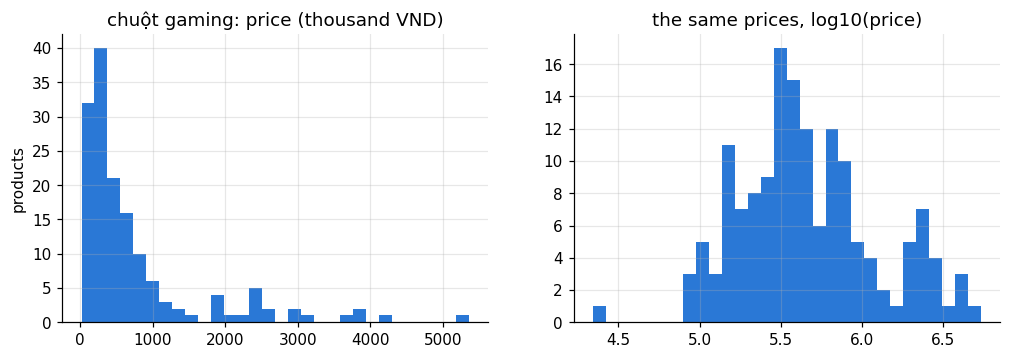

Skewness of price:        2.4
Skewness of log10(price): 0.32


In [5]:
prices = df.loc[df["keyword"] == "chuột gaming", "price"]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.hist(prices / 1000, bins=30, color=COLORS["chuột gaming"])
left.set(title="chuột gaming: price (thousand VND)", ylabel="products")
right.hist(np.log10(prices), bins=30, color=COLORS["chuột gaming"])
right.set(title="the same prices, log10(price)")
plt.show()

print("Skewness of price:       ", round(prices.skew(), 2))
print("Skewness of log10(price):", round(np.log10(prices).skew(), 2))

Prices are **right-skewed**: many cheap products, a few very expensive ones (skewness 2.4). On a log scale the shape is close to symmetric (0.32), so the IQR rule for unusual prices (`analysis.flag_prices`) is applied to `log10(price)`: a price more than 1.5 IQR below Q1 or above Q3 is *unusual*.

In [6]:
df["price_flag"] = df.groupby("keyword")["price"].transform(flag_prices)

rows = []
for keyword, group in df.groupby("keyword", sort=False):
    low, high = price_fences(group["price"])
    rows.append({"keyword": keyword, "lowest normal price": short(low), "highest normal price": short(high),
                 "unusual": int((group["price_flag"] != "normal").sum()), "products": len(group)})
pd.DataFrame(rows).set_index("keyword")

,lowest normal price,highest normal price,unusual,products
keyword,,,,
chuột gaming,40K,4.77M,2,152
tai nghe bluetooth,153K,5.62M,4,70
nồi chiên không dầu,651K,12.83M,2,188


In [7]:
df.loc[df["price_flag"] != "normal", ["keyword", "name", "price", "price_flag"]].sort_values(["keyword", "price"])

,keyword,name,price,price_flag
69,chuột gaming,Chuột Game Chuyên Dụng Đèn Led - Màu ngẫu nhiên,22093,low
109,chuột gaming,Chuột không dây Gaming Logitech Pro X2 Superst...,5359000,high
249,nồi chiên không dầu,"Nồi Chiên Không Dầu 8L , Nướng Gà Cả Con - Bếp...",599000,low
231,nồi chiên không dầu,"Nồi chiên không dầu thế hệ mới dung tích lớn, ...",650000,low
197,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Xiaomi FlipBu...,5990000,high
210,tai nghe bluetooth,Tai nghe Bluetooth Apple AirPods Pro 3 - MFHP4...,6250000,high
208,tai nghe bluetooth,Tai nghe Bluetooth True Wireless JBL Live Beam...,6290000,high
221,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Sony WF-1000X...,9564000,high


Only **8 of 410** products are flagged, and they are of two kinds:

- **too expensive (5):** real flagship products (Logitech Pro X2, AirPods Pro 3, Sony WF-1000XM6...) that cost far more than what most people compare;
- **too cheap (3):** no-name products far below the rest (a 22K gaming mouse, two air fryers at 599K and 650K).

They are kept in the data but left out of the reference prices below.

**So what?** One very cheap or very expensive listing would otherwise move the "fair price"; the log-scale rule removes only a handful of clear outliers.

## 3. Reference prices

Computed on normal prices only, rounded to 1 000 VND (`analysis.reference_prices`):

- **floor price** = 10th percentile: 90 % of listings cost more;
- **common range** = Q1 to Q3: the middle 50 % of listings;
- **median**: half of the listings are cheaper, half are more expensive.

In [8]:
normal = df[df["price_flag"] == "normal"]

bands = {}
for keyword, group in normal.groupby("keyword", sort=False):
    bands[keyword] = reference_prices(group["price"])
bands = pd.DataFrame(bands).T[["floor", "q1", "median", "q3"]]
bands.map(short)

,floor,q1,median,q3
chuột gaming,150K,244K,398K,793K
tai nghe bluetooth,354K,568K,699K,1.31M
nồi chiên không dầu,1.37M,1.99M,2.69M,4.2M


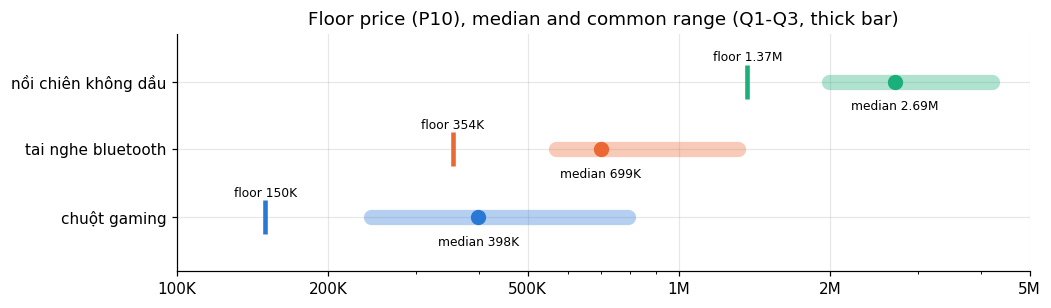

In [9]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, keyword in enumerate(bands.index):
    band = bands.loc[keyword]
    color = COLORS[keyword]
    ax.plot([band["q1"], band["q3"]], [y, y], color=color, linewidth=10, alpha=0.35, solid_capstyle="round")
    ax.plot(band["median"], y, "o", color=color, markersize=9)
    ax.plot(band["floor"], y, "|", color=color, markersize=22, markeredgewidth=3)
    ax.text(band["floor"], y + 0.3, f"floor {short(band['floor'])}", ha="center", fontsize=8)
    ax.text(band["median"], y - 0.42, f"median {short(band['median'])}", ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks([100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000])
ax.xaxis.set_major_formatter(lambda x, _: short(x))
ax.set_yticks(range(len(bands)), bands.index)
ax.set_ylim(-0.8, len(bands) - 0.3)
ax.set_title("Floor price (P10), median and common range (Q1-Q3, thick bar)")
fig.savefig(FIGURES / "reference_prices.png", bbox_inches="tight")
plt.show()

| keyword | floor price (P10) | common range (Q1–Q3) | median |
|---|---|---|---|
| chuột gaming | 150K | 244K – 793K | 398K |
| tai nghe bluetooth (true wireless) | 354K | 568K – 1.31M | 699K |
| nồi chiên không dầu | 1.37M | 1.99M – 4.2M | 2.69M |

**So what?** A shopper can see at once that a gaming mouse under 150K or an air fryer under 1.37M is cheaper than 90 % of the listings: worth a closer look (accessory? old model? used?). A seller can see where most competitors price.

## 4. Which price segment sells?

Segments are cut at Q1 and Q3 (`analysis.price_segments`): **budget** (cheapest 25 %), **mid** (middle 50 %), **premium** (most expensive 25 %). If buyers did not care about price, each segment's share of units sold would equal its share of listings.

In [10]:
tables = []
for keyword, group in normal.groupby("keyword", sort=False):
    table = price_segments(group, reference_prices(group["price"]))
    table.insert(0, "keyword", keyword)
    tables.append(table)
segments = pd.concat(tables).set_index(["keyword", "segment"])
segments[["listings", "sold", "listing_share", "sold_share"]].round(1)

listings  sold  listing_share  sold_share
keyword             segment                                           
chuột gaming        budget         38   553           25.3         4.3
                    mid            74  7328           49.3        57.4
                    premium        38  4883           25.3        38.3
tai nghe bluetooth  budget         17  1310           25.8        51.0
                    mid            32   342           48.5        13.3
                    premium        17   919           25.8        35.7
nồi chiên không dầu budget         48   269           25.8         3.1
                    mid            91  8460           48.9        96.5
                    premium        47    35           25.3         0.4

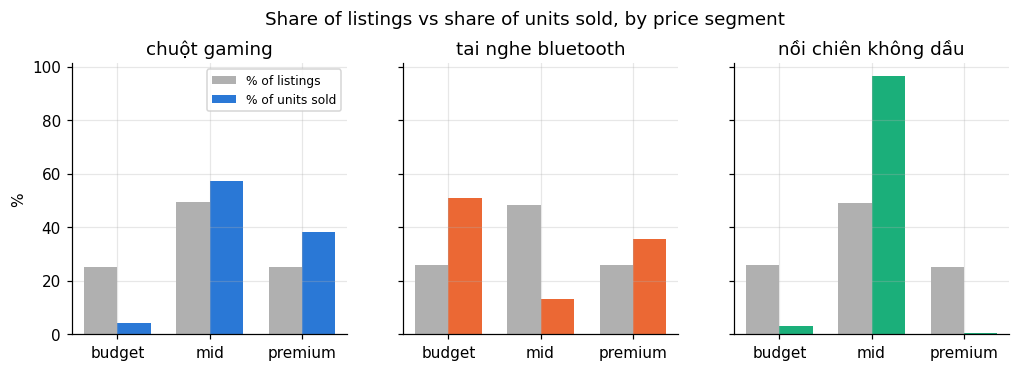

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
x = np.arange(3)
for ax, keyword in zip(axes, bands.index):
    table = segments.loc[keyword]
    ax.bar(x - 0.18, table["listing_share"], width=0.36, color="#b0b0b0", label="% of listings")
    ax.bar(x + 0.18, table["sold_share"], width=0.36, color=COLORS[keyword], label="% of units sold")
    ax.set_xticks(x, ["budget", "mid", "premium"])
    ax.set_title(keyword)
axes[0].set_ylabel("%")
axes[0].legend(fontsize=8)
fig.suptitle("Share of listings vs share of units sold, by price segment", y=1.03)
fig.savefig(FIGURES / "segments.png", bbox_inches="tight")
plt.show()

The coloured bars do not match the gray ones:

- **Gaming mice:** the cheapest quarter of listings gets only **4.3 %** of units sold; mid and premium sell more than their share.
- **Earbuds:** the budget segment gets **51 %** of units, but mostly through *one* product (next section).
- **Air fryers:** the mid segment takes **96.5 %** of units, again because of one product.

**So what?** "Cheapest" is not what sells for gaming mice: a seller should not simply undercut. But the next section shows these shares depend on very few products, so they describe the best sellers more than the whole market.

## 5. How concentrated are sales?

`sold` is the total number of units a listing has ever sold (cumulative, as shown on Tiki).

In [12]:
rows = []
for keyword, group in normal.groupby("keyword", sort=False):
    sold = group["sold"].sort_values(ascending=False)
    best = group.loc[group["sold"].idxmax()]
    top_10_percent = sold.head(round(len(sold) * 0.10))
    rows.append({
        "keyword": keyword,
        "best seller": best["name"],
        "its price": short(best["price"]),
        "its share of units %": round(100 * best["sold"] / sold.sum(), 1),
        "top 10% of listings: share of units %": round(100 * top_10_percent.sum() / sold.sum(), 1),
        "never sold %": round(100 * (sold == 0).mean(), 1),
    })
concentration = pd.DataFrame(rows).set_index("keyword")
concentration

,best seller,its price,its share of units %,top 10% of listings: share of units %,never sold %
keyword,,,,,
chuột gaming,Chuột Gaming Logitech G102 Gen 2 Lightsync - H...,472K,37.3,95.5,39.3
tai nghe bluetooth,Tai Nghe Bluetooth Cao Cấp EQ2 5.3 Pin 7h Âm T...,359K,44.6,91.0,37.9
nồi chiên không dầu,Nồi Chiên Không Dầu Điện Tử Lock&Lock EJF296BL...,2.17M,87.6,99.2,68.8


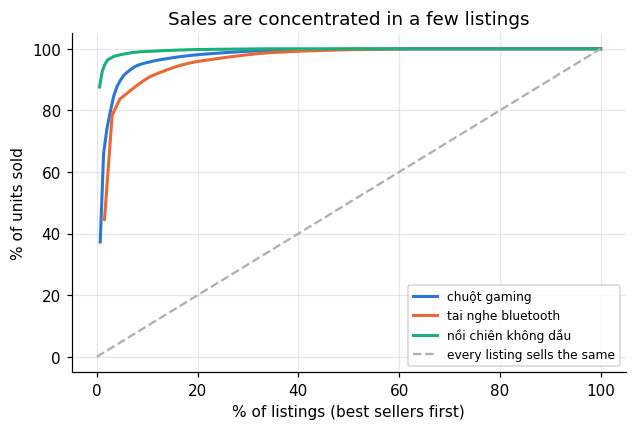

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for keyword, group in normal.groupby("keyword", sort=False):
    sold = group["sold"].sort_values(ascending=False).to_numpy()
    share_of_listings = 100 * np.arange(1, len(sold) + 1) / len(sold)
    share_of_units = 100 * sold.cumsum() / sold.sum()
    ax.plot(share_of_listings, share_of_units, color=COLORS[keyword], linewidth=2, label=keyword)
ax.plot([0, 100], [0, 100], color="#b0b0b0", linestyle="--", label="every listing sells the same")
ax.set(xlabel="% of listings (best sellers first)", ylabel="% of units sold",
       title="Sales are concentrated in a few listings")
ax.legend(fontsize=8)
fig.savefig(FIGURES / "concentration.png", bbox_inches="tight")
plt.show()

- **One product sells 37 % (mice), 45 % (earbuds) and 88 % (air fryers) of all units.** For air fryers it is a Lock&Lock model at 2.17M: that one product is why the mid segment takes 96.5 % of units.
- The **top 10 % of listings** take **91–99 %** of units sold.
- **38–69 %** of listings have **never sold** a single unit.

**So what?** These markets are *winner-take-most*. For a new seller, being one more listing in the common price range is not enough: the few best sellers have the reviews and the sales history. Any number weighted by sales (like the segment shares above) mostly describes those few products.

## 6. What goes together with sales?

Spearman correlation (ρ, based on ranks) is used because sales and prices are very skewed and the relationships do not need to be straight lines. Many products have 0 sold *and* 0 reviews, and such a big block of ties can inflate a rank correlation, so ρ is also computed on products that sold at least once.

In [14]:
rows = []
for keyword, group in normal.groupby("keyword", sort=False):
    sold_once = group[group["sold"] > 0]
    rows.append({
        "keyword": keyword,
        "rated %": round(100 * group["rating"].notna().mean(), 1),
        "median rating": group["rating"].median(),
        "ρ reviews ~ sold (all)": round(group["review_count"].corr(group["sold"], method="spearman"), 2),
        "ρ reviews ~ sold (sold > 0)": round(sold_once["review_count"].corr(sold_once["sold"], method="spearman"), 2),
        "ρ price ~ sold": round(group["price"].corr(group["sold"], method="spearman"), 2),
    })
pd.DataFrame(rows).set_index("keyword")

,rated %,median rating,ρ reviews ~ sold (all),ρ reviews ~ sold (sold > 0),ρ price ~ sold
keyword,,,,,
chuột gaming,38.7,5.0,0.82,0.79,-0.17
tai nghe bluetooth,47.0,5.0,0.88,0.83,-0.24
nồi chiên không dầu,15.1,5.0,0.71,0.70,-0.20


- **Reviews ↔ sold: ρ = 0.71 to 0.88** on all products, and still **0.70 to 0.83** on products that sold at least once, so it is not only the block of (0 sold, 0 reviews). A review needs a purchase, so this is mostly a consistency check of the data, not a cause of sales.
- **Star ratings say little:** only 15–47 % of products are rated and the median rating is **5.0**, so ratings hardly separate products.
- **Price ↔ sold: ρ = −0.24 to −0.17**: cheaper products sell a little more, but the link is weak.

In [15]:
# Discounted vs not discounted
data = normal.assign(discounted=normal["discount_pct"] > 0)
data.groupby(["keyword", "discounted"], sort=False).agg(products=("price", "size"), median_sold=("sold", "median"))

products  median_sold
keyword             discounted                       
chuột gaming        False            136          1.0
                    True              14          2.0
tai nghe bluetooth  True              12         12.5
                    False             54          1.0
nồi chiên không dầu True              42          1.0
                    False            144          0.0

Discounted products have a higher median number sold (earbuds: 12.5 vs 1). This is a **correlation, not proof that discounts cause sales**: sellers may put discounts on products that already sell, and `sold` counts sales from before the discount started.

**So what?** For a shopper, the number of reviews is a better signal than the star rating. To know whether discounts really increase sales, the same products would have to be followed over several days (see Limitations in the README).

## Conclusions

1. **A floor price can be estimated from listings alone:** gaming mouse ≈ 150K, true-wireless earbuds ≈ 354K, air fryer ≈ 1.37M (10th percentile of normal prices). Cheaper listings deserve a closer look.
2. **Prices are right-skewed**, so unusual prices are found on `log10(price)`; only 8 of 410 products are flagged.
3. **The cheapest is not what sells** for gaming mice (budget quarter: 4.3 % of units).
4. **Sales are winner-take-most:** one product takes 37–88 % of units and 38–69 % of listings never sold, so sales-weighted numbers describe a few best sellers.
5. **Reviews follow sales (ρ 0.70–0.88), star ratings do not separate products** (median 5.0).

**Limits:** one moment in time; `sold` is cumulative; only the first 200 results of Tiki's ranking; one category per keyword.